# 自制语言模型的知识蒸馏（CPU）

本 Notebook 是统一入口：按顺序执行即可完成环境检查、正式对照、16组消融、拓展和报告数据导出。本次正式运行已完成，下面保留实际执行顺序、原始输出和运行后分析。结果图表和汇总数据另存于 `results/`；重新运行生成的缓存保存在 `runs_distill/`。

实验实现见同目录 `distill_lm.py`。先阅读模型、数据、蒸馏损失和训练函数，再运行下面的单元格。教师与学生分别为2层、4头、宽度160和64，上下文96。训练和留出语料文法相同、随机种子不同；两者仍共享固定古诗片段，因此留出集并非完全无重叠，分析时需保留这一局限。

建议 Python 3.10–3.12，CPU PyTorch ≥2.2，另需 matplotlib、IPython、ipykernel。若环境缺依赖，在所选内核对应的环境安装：
```text
python -m pip install torch --index-url https://download.pytorch.org/whl/cpu
python -m pip install matplotlib ipykernel
```
无需下载预训练模型或外部数据。先保存 Notebook，运行后再次保存，以保留过程和输出。

In [1]:
from pathlib import Path
import sys, json, time, traceback
from contextlib import contextmanager
from IPython.display import display, Markdown

# 兼容从仓库根目录或 Notebook 所在目录启动。
ROOT = Path.cwd()
LAB = ROOT if (ROOT / 'distill_lm.py').exists() else ROOT / 'labs' / '08-knowledge-distillation'
if not (LAB / 'distill_lm.py').exists():
    raise FileNotFoundError('请将内核工作目录设为本 Notebook 目录或仓库根目录。')
sys.path.insert(0, str(LAB))
from distill_lm import Config, Experiment, kd_loss, plot_results
import torch

CFG = Config()  # 正式默认参数；改参数后请修改 RUN_NAME，避免混用缓存。
RUN_NAME = 'formal'
exp = Experiment(CFG, LAB / 'runs_distill' / RUN_NAME)
operations_path = exp.output / 'operations.json'
operations = json.loads(operations_path.read_text(encoding='utf-8')) if operations_path.exists() else []

@contextmanager
def step(label, command):
    start = time.perf_counter()
    row = {'step': label, 'notebook_operation': command, 'success': False}
    try:
        yield
        row['success'] = True
    except Exception:
        row['error'] = traceback.format_exc()
        raise
    finally:
        row['elapsed_s'] = time.perf_counter() - start
        operations.append(row)
        exp.write_json('operations.json', operations)
        print(f"{label}: 成功={row['success']}, 本次执行耗时={row['elapsed_s']:.2f}s")

def show(rows):
    # 使用 Markdown 展示，不额外依赖 pandas。
    if isinstance(rows, dict):
        rows = [rows]
    simple = [{k:v for k,v in r.items() if not isinstance(v, (dict,list))} for r in rows]
    keys = list(dict.fromkeys(k for r in simple for k in r))
    def fmt(v):
        return str(round(v, 6) if isinstance(v, float) else v).replace('|','／').replace('\n','<br>')
    display(Markdown('| ' + ' | '.join(keys) + ' |\n|' + '|'.join(['---']*len(keys)) + '|\n' +
                     '\n'.join('| ' + ' | '.join(fmt(r.get(k,'')) for k in keys) + ' |' for r in simple)))
show(exp.environment)
print('正式参数：', CFG)


| os | python | torch | cpu | logical_cores | threads | device | train_chars | val_chars | vocab |
|---|---|---|---|---|---|---|---|---|---|
| Windows 11 | 3.13.3 | 2.6.0+cu124 | Intel64 Family 6 Model 183 Stepping 1, GenuineIntel | 24 | 4 | CPU | 52456 | 5656 | 322 |

正式参数： Config(seed=0, block_size=96, batch_size=24, teacher_iters=200, student_iters=120, abl_iters=80, lr=0.003, temperature=4.0, alpha=0.5, eval_iters=20, threads=4)


## 1. 环境与正确性自检

自检使用独立 `quick/` 目录和极少步数，只验证运行链路，结果不能作为正式结论。另检查：相同 logits 的 KL 约为0，KL 按 token 平均，两名学生初始化与批次采样一致。

In [2]:
with step('1. 环境自检', 'quick.baseline()；等价入口 python distill_lm.py --mode quick'):
    quick = Experiment(Config(teacher_iters=2, student_iters=2, abl_iters=2,
                              eval_iters=1, batch_size=2), LAB / 'runs_distill' / 'quick')
    quick_models, quick_rows = quick.baseline()
    z = torch.randn(2, 3, 7)
    assert abs(kd_loss(z, z, 4).item()) < 1e-5
    other = torch.randn_like(z)
    assert torch.allclose(kd_loss(z, other, 4), kd_loss(z.repeat(2,1,1), other.repeat(2,1,1), 4), atol=1e-6)
    a = exp.new_model(64, CFG.seed + 7)
    b = exp.new_model(64, CFG.seed + 7)
    assert all(torch.equal(x,y) for x,y in zip(a.parameters(), b.parameters()))
    from distill_lm import batch
    ga = torch.Generator().manual_seed(CFG.seed + 1)
    gb = torch.Generator().manual_seed(CFG.seed + 1)
    assert all(torch.equal(batch(exp.train_ids, CFG, ga)[0], batch(exp.train_ids, CFG, gb)[0]) for _ in range(3))
    show(quick_rows)
    del quick_models, a, b


teacher: 复用已完成记录，原训练耗时 0.51s
scratch: 复用已完成记录，原训练耗时 0.11s
kd: 复用已完成记录，原训练耗时 0.17s


| name | params | steps | time_s | final_train_loss | final_train_ce | val_loss | ppl | agree |
|---|---|---|---|---|---|---|---|---|
| teacher | 737280 | 2 | 0.507717 | 5.61912 | 5.61912 | 5.311337 | 202.621047 | None |
| scratch | 147456 | 2 | 0.111243 | 5.732217 | 5.732217 | 5.616666 | 274.971187 | 0.067708 |
| kd | 147456 | 2 | 0.17285 | 2.88918 | 5.73209 | 5.617167 | 275.108894 | 0.067708 |

1. 环境自检: 成功=True, 本次执行耗时=0.13s


## 2. 模型参数与原理

蒸馏目标为 `(1−α) CE + α T² KL(p_teacher^T || p_student^T)`。输入 `kl_div` 的是学生的 log 概率和教师的概率，先展平成 `(batch×sequence, vocab)`，避免序列长度放大损失。教师不参与反向传播。

手算近似：`2VC + block_size×C + 2×12C²`。以下同时列出实际参数量、误差和压缩比，填入报告表五。误差来自偏置与 LayerNorm 等项；词表以实际构造结果为准。

**手算核对补充：** 上式忽略偏置与LayerNorm，教师近似误差0.608%，学生误差1.215%。每个Transformer层额外有13C参数，两层为26C，最终LayerNorm再加2C。因此精确公式为 `2VC + block_size×C + 24C² + 28C`；教师737,280、学生147,456，与下方实际计数完全一致。保留下方原始近似输出，不修改实验事实。

In [3]:
import inspect
from distill_lm import build_corpus, GPT, Block, train, evaluate
# 展示实际执行的关键实现，方便在 Notebook 中直接阅读核对。
for obj in (build_corpus, Block, GPT, kd_loss, train, evaluate):
    display(Markdown("### " + obj.__name__ + "\n```python\n" + inspect.getsource(obj) + "\n```"))


### build_corpus
```python
def build_corpus(n_lines=3000, seed=0):
    rng = random.Random(seed)
    out = []
    for i in range(n_lines):
        s, p, v, o, m = (rng.choice(x) for x in (SUBJ, PLACE, VERB, OBJ, MOOD))
        if i % 3 == 0:
            out.append(f'{s}{p}{v}{o}，{m}。')
        elif i % 3 == 1:
            out.append(f'{s}在{p}{o}了一夜{rng.choice(["看", "听", "守", "忆"])}，{m}。')
        else:
            out.append(f'{s}{v}道：“{o}{rng.choice(["正好", "可怜", "可惜", "依旧"])}。”{m}。')
        out.append('\n')
    return ''.join(out + POEMS)

```

### Block
```python
class Block(nn.Module):
    def __init__(self, width, block):
        super().__init__()
        self.ln1 = nn.LayerNorm(width)
        self.qkv = nn.Linear(width, 3 * width)
        self.proj = nn.Linear(width, width)
        self.ln2 = nn.LayerNorm(width)
        self.mlp = nn.Sequential(nn.Linear(width, 4 * width), nn.GELU(), nn.Linear(4 * width, width))
        self.register_buffer('mask', torch.tril(torch.ones(block, block)).bool().view(1, 1, block, block))

    def forward(self, x):
        b, t, c = x.shape
        q, k, v = [z.view(b, t, 4, c // 4).transpose(1, 2) for z in self.qkv(self.ln1(x)).chunk(3, dim=-1)]
        a = (q @ k.transpose(-2, -1)) / math.sqrt(c // 4)
        a = a.masked_fill(~self.mask[:, :, :t, :t], float('-inf')).softmax(-1)
        x = x + self.proj((a @ v).transpose(1, 2).contiguous().view(b, t, c))
        return x + self.mlp(self.ln2(x))

```

### GPT
```python
class GPT(nn.Module):
    def __init__(self, vocab, width, block=96):
        super().__init__()
        self.width, self.block = width, block
        self.tok_emb = nn.Embedding(vocab, width)
        self.pos_emb = nn.Embedding(block, width)
        self.blocks = nn.ModuleList([Block(width, block) for _ in range(2)])
        self.ln_f = nn.LayerNorm(width)
        self.head = nn.Linear(width, vocab, bias=False)
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, std=.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, idx, hidden=False):
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(idx.size(1)))
        for layer in self.blocks:
            x = layer(x)
        x = self.ln_f(x)
        logits = self.head(x)
        return (logits, x) if hidden else logits

```

### kd_loss
```python
def kd_loss(student, teacher, temperature):
    # KL(p_teacher || p_student)，按 token 平均，避免序列长度放大 KL。
    v = student.size(-1)
    return F.kl_div(F.log_softmax(student.reshape(-1, v) / temperature, -1),
                    F.softmax(teacher.reshape(-1, v) / temperature, -1),
                    reduction='batchmean') * temperature ** 2

```

### train
```python
def train(model, data, cfg, steps, teacher=None, temperature=4., alpha=.5, feat=0., cache=None):
    model.train()
    if teacher is not None:
        teacher.eval()
    projection = nn.Linear(model.width, teacher.width) if feat else None
    params = list(model.parameters()) + (list(projection.parameters()) if projection is not None else [])
    opt = torch.optim.AdamW(params, lr=cfg.lr, weight_decay=.01)
    gen = torch.Generator().manual_seed(cfg.seed + 1)
    history = {'objective': [], 'ce': [], 'kd': [], 'feature': []}
    start = time.perf_counter()
    for i in range(steps):
        if cache is None:
            x, y = batch(data, cfg, gen)
            tl = None
        else:
            x, y, tl = cache[i % len(cache)]
        z, hs = model(x, hidden=True)
        ce = F.cross_entropy(z.reshape(-1, z.size(-1)), y.reshape(-1))
        kd, fm = z.new_zeros(()), z.new_zeros(())
        if teacher is not None or tl is not None:
            if tl is None:
                with torch.no_grad():
                    tl, ht = teacher(x, hidden=True)
            kd = kd_loss(z, tl, temperature)
            loss = (1 - alpha) * ce + alpha * kd
            if projection is not None:
                fm = F.mse_loss(projection(hs), ht)
                loss = loss + feat * fm
        else:
            loss = ce
        opt.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(params, 1.)
        opt.step()
        for key, value in zip(history, (loss, ce, kd, fm)):
            history[key].append(value.item())
        if i == 0 or (i + 1) % 50 == 0 or i + 1 == steps:
            print(f'  {i+1}/{steps}: objective={loss.item():.4f}, CE={ce.item():.4f}', flush=True)
    return history, time.perf_counter() - start

```

### evaluate
```python
@torch.no_grad()
def evaluate(model, data, cfg, teacher=None):
    model.eval()
    if teacher is not None:
        teacher.eval()
    gen = torch.Generator().manual_seed(1234)
    losses, hit, count = [], 0, 0
    for _ in range(cfg.eval_iters):
        x, y = batch(data, cfg, gen)
        z = model(x)
        losses.append(F.cross_entropy(z.reshape(-1, z.size(-1)), y.reshape(-1)).item())
        if teacher is not None:
            hit += (z.argmax(-1) == teacher(x).argmax(-1)).sum().item()
            count += y.numel()
    loss = sum(losses) / len(losses)
    return {'val_loss': loss, 'ppl': math.exp(loss), 'agree': hit / count if count else None}

```

In [4]:
parameters = exp.parameter_table()
show(parameters)
show({'T':CFG.temperature, 'alpha':CFG.alpha, 'lr':CFG.lr, 'batch_size':CFG.batch_size,
      'teacher_steps':CFG.teacher_iters, 'student_steps':CFG.student_iters,
      'ablation_steps':CFG.abl_iters, 'seed':CFG.seed, 'feature_weight_baseline':0})

| model | n_layer | n_head | n_embd | block_size | vocab | params | approx_params | relative_error_percent | compression_ratio |
|---|---|---|---|---|---|---|---|---|---|
| teacher | 2 | 4 | 160 | 96 | 322 | 737280 | 732800 | 0.607639 |  |
| student | 2 | 4 | 64 | 96 | 322 | 147456 | 145664 | 1.215278 | 5.0 |

| T | alpha | lr | batch_size | teacher_steps | student_steps | ablation_steps | seed | feature_weight_baseline |
|---|---|---|---|---|---|---|---|---|
| 4.0 | 0.5 | 0.003 | 24 | 200 | 120 | 80 | 0 | 0 |

## 3. 教师训练

正式教师训练200步。记录最终训练损失、留出 loss/PPL、参数量和原始训练耗时。完整缓存存在且配置相同时复用；耗时仍读取首次训练记录。需要重训时使用 `force=True`；重训后应重新运行后续各步，教师权重不同的缓存会拒绝复用。

In [5]:
with step('2. 训练教师', "exp.fit('teacher', 160, CFG.teacher_iters)"):
    teacher, teacher_row = exp.fit('teacher', 160, CFG.teacher_iters)
    show(teacher_row)

开始 teacher
  1/200: objective=5.8247, CE=5.8247
  50/200: objective=1.3378, CE=1.3378
  100/200: objective=0.7932, CE=0.7932
  150/200: objective=0.7316, CE=0.7316
  200/200: objective=0.7159, CE=0.7159


| name | params | steps | time_s | final_train_loss | final_train_ce | val_loss | ppl | agree |
|---|---|---|---|---|---|---|---|---|
| teacher | 737280 | 200 | 7.716663 | 0.715914 | 0.715914 | 0.832208 | 2.298388 | None |

2. 训练教师: 成功=True, 本次执行耗时=10.37s


## 4. 从零学生与蒸馏学生

两组学生的架构、初始化种子、数据顺序、优化器及训练步数一致，区别是是否使用教师软标签。评价统一使用固定留出批次。训练目标数值的定义不同，不能只比较总损失曲线高低。

teacher: 复用已完成记录，原训练耗时 7.72s
开始 scratch
  1/120: objective=5.7839, CE=5.7839
  50/120: objective=1.7239, CE=1.7239
  100/120: objective=1.0905, CE=1.0905
  120/120: objective=0.9982, CE=0.9982
开始 kd
  1/120: objective=5.6560, CE=5.7839
  50/120: objective=2.0596, CE=1.8565
  100/120: objective=1.0640, CE=1.0717
  120/120: objective=0.8805, CE=0.9446


| name | params | steps | time_s | final_train_loss | final_train_ce | val_loss | ppl | agree |
|---|---|---|---|---|---|---|---|---|
| teacher | 737280 | 200 | 7.716663 | 0.715914 | 0.715914 | 0.832208 | 2.298388 | None |
| scratch | 147456 | 120 | 2.046748 | 0.998225 | 0.998225 | 1.272223 | 3.568778 | 0.63878 |
| kd | 147456 | 120 | 3.771017 | 0.880451 | 0.944624 | 1.210737 | 3.355957 | 0.686133 |

| loss_change_kd_minus_scratch | loss_reduction_percent | ppl_change_kd_minus_scratch | agreement_change |
|---|---|---|---|
| -0.061486 | 4.832994 | -0.212822 | 0.047352 |

| model | prompt | new_characters | temperature | top_k | seed | continuation |
|---|---|---|---|---|---|---|
| teacher | 月 | 60 | 0.9 | 20 | 2026 | 可怜。”此意难平。<br>故人长亭听见细雨，忽忆旧游。<br>渔夫在溪桥残灯了一夜看，不觉天明。<br>游子空忆道：“白雪可怜。”忽忆旧游 |
| scratch | 月 | 60 | 0.9 | 20 | 2026 | ，不觉天明。<br>诗人在舟中惆怅。<br>归客野渡疏星了一夜听，心中惆怅。草，长叹一夜守，心中惆怅。<br>少年听，长亭远在城楼疏星，此 |
| kd | 月 | 60 | 0.9 | 20 | 2026 | 依旧游。<br>小红松间空忆秋草，长叹一声。<br>旅人在舟中秋草，默然无语。<br>旅人在舟依旧。<br>故人恰遇道：“残灯，泪湿衣襟。<br>少年 |

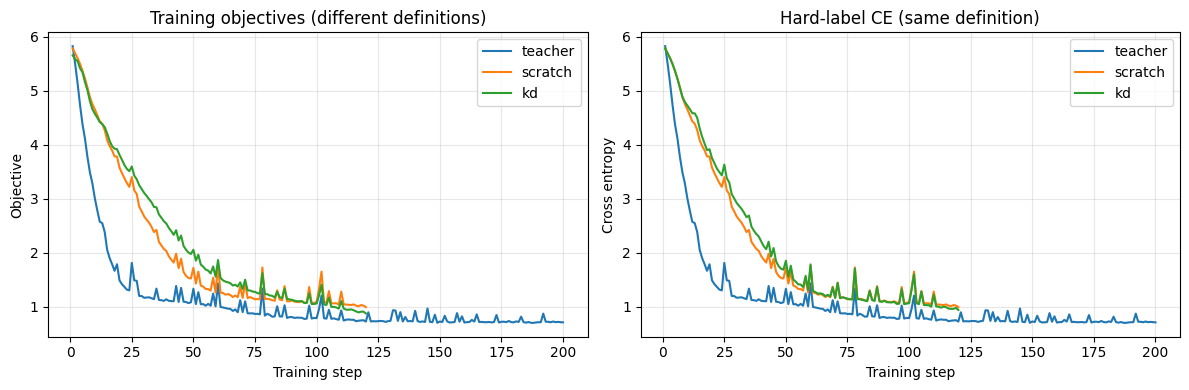

3. 从零与蒸馏: 成功=True, 本次执行耗时=7.94s


In [6]:
with step('3. 从零与蒸馏', 'exp.baseline()'):
    models, baseline_rows = exp.baseline()
    teacher, scratch, distilled = models
    show(baseline_rows)
    scratch_row, kd_row = baseline_rows[1:]
    comparison = {
        'loss_change_kd_minus_scratch':kd_row['val_loss']-scratch_row['val_loss'],
        'loss_reduction_percent':100*(scratch_row['val_loss']-kd_row['val_loss'])/scratch_row['val_loss'],
        'ppl_change_kd_minus_scratch':kd_row['ppl']-scratch_row['ppl'],
        'agreement_change':kd_row['agree']-scratch_row['agree']}
    show(comparison)
    exp.write_json('comparison.json', comparison)
    samples = exp.samples(models)
    show(samples)
    plot_results(baseline_rows, [], exp.output)

**运行后分析：** 相同147,456参数、120步、初始化种子7和采样种子1下，蒸馏将留出loss从1.272223降至1.210737，下降4.8330%；PPL从3.568778降至3.355957；教师一致率从63.8780%升至68.6133%，提高4.7352个百分点。教师留出loss为0.832208，具备较好的监督能力。此结果支持当前训练预算下输出层蒸馏有效，但单种子结果不能用于声称统计显著性。

右侧硬标签CE曲线具有相同定义：两组学生早期都有批次波动，后期蒸馏学生略低，不能声称每一步都收敛更快。左侧混合目标与普通CE定义不同，不直接比较绝对值。

教师样例较好保持槽位句式；从零学生出现“草，长叹一夜守”等错拼；蒸馏学生有“小红松间空忆秋草，长叹一声”等完整片段，但仍出现“旅人在舟依旧”等残缺。局部句式有所改善，不代表已具备稳定语法。合成文法本身也有不自然表达。样例仅为一次采样，首尾还受单字提示和截断长度影响。

生成结果记录提示字“月”之外新增的60个字符（包含标点和换行）。

## 5. 温度 × 权重：16组消融及热力图（拓展B）

温度 `{1,2,4,8}`，权重 `{0.3,0.5,0.7,0.9}`，各训练80步。统一缓存32批数据和教师 logits，各组使用相同初始化与缓存顺序。此训练数据循环方式与主实验不同，只在本消融内部比较。逐组落盘，意外中断后重新执行可复用已完成组。

ablate_T1_a0.3
  1/80: objective=5.5634, CE=5.7845
  50/80: objective=1.2311, CE=1.4440
  80/80: objective=0.8942, CE=1.1003
ablate_T1_a0.5
  1/80: objective=5.4160, CE=5.7845
  50/80: objective=1.0768, CE=1.4341
  80/80: objective=0.7534, CE=1.0996
ablate_T1_a0.7
  1/80: objective=5.2685, CE=5.7845
  50/80: objective=0.9244, CE=1.4280
  80/80: objective=0.6136, CE=1.1028
ablate_T1_a0.9
  1/80: objective=5.1211, CE=5.7845
  50/80: objective=0.7753, CE=1.4279
  80/80: objective=0.4726, CE=1.1083
ablate_T2_a0.3
  1/80: objective=7.6193, CE=5.7845
  50/80: objective=2.0666, CE=1.4607
  80/80: objective=1.2297, CE=1.0850
ablate_T2_a0.5
  1/80: objective=8.8425, CE=5.7845
  50/80: objective=2.4446, CE=1.4870
  80/80: objective=1.2724, CE=1.0942
ablate_T2_a0.7
  1/80: objective=10.0657, CE=5.7845
  50/80: objective=2.8272, CE=1.5328
  80/80: objective=1.3061, CE=1.1112
ablate_T2_a0.9
  1/80: objective=11.2889, CE=5.7845
  50/80: objective=3.2160, CE=1.5930
  80/80: objective=1.3338, CE=1.135

| T | alpha | steps | time_s | val_loss | ppl | agree |
|---|---|---|---|---|---|---|
| 1 | 0.3 | 80 | 1.481503 | 1.420672 | 4.139902 | None |
| 1 | 0.5 | 80 | 1.536298 | 1.418925 | 4.132674 | None |
| 1 | 0.7 | 80 | 1.532953 | 1.419865 | 4.136563 | None |
| 1 | 0.9 | 80 | 1.556934 | 1.421334 | 4.142643 | None |
| 2 | 0.3 | 80 | 1.507512 | 1.427273 | 4.16732 | None |
| 2 | 0.5 | 80 | 1.531974 | 1.439673 | 4.219314 | None |
| 2 | 0.7 | 80 | 1.505522 | 1.458646 | 4.300134 | None |
| 2 | 0.9 | 80 | 1.565448 | 1.487597 | 4.426447 | None |
| 4 | 0.3 | 80 | 1.534547 | 1.402372 | 4.064831 | None |
| 4 | 0.5 | 80 | 1.553924 | 1.402841 | 4.066739 | None |
| 4 | 0.7 | 80 | 1.573076 | 1.426183 | 4.162778 | None |
| 4 | 0.9 | 80 | 14.360309 | 1.539104 | 4.660412 | None |
| 8 | 0.3 | 80 | 7.832418 | 1.400758 | 4.058277 | None |
| 8 | 0.5 | 80 | 7.810895 | 1.404068 | 4.071729 | None |
| 8 | 0.7 | 80 | 12.347026 | 1.43599 | 4.203804 | None |
| 8 | 0.9 | 80 | 14.233792 | 1.672261 | 5.324193 | None |

| position | T | alpha | val_loss |
|---|---|---|---|
| best | 8 | 0.3 | 1.400758 |
| worst | 8 | 0.9 | 1.672261 |

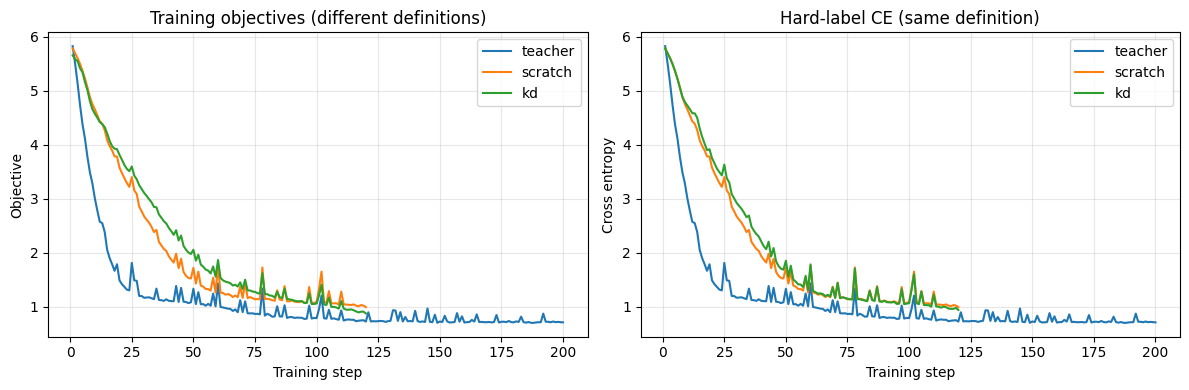

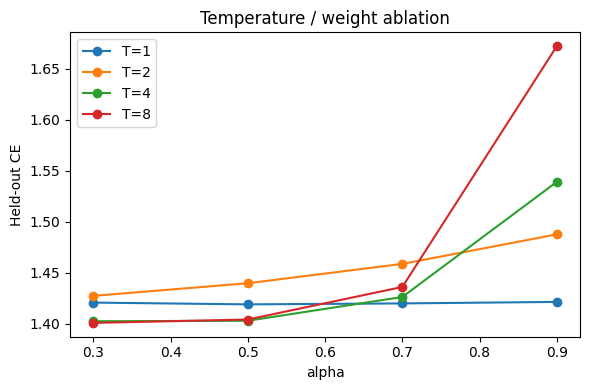

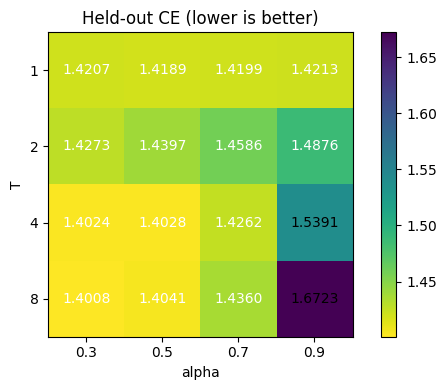

4. 消融实验: 成功=True, 本次执行耗时=84.29s


In [7]:
with step('4. 消融实验', 'exp.ablate(teacher)'):
    ablation = exp.ablate(teacher)
    show(ablation)
    best = min(ablation, key=lambda r:r['val_loss'])
    worst = max(ablation, key=lambda r:r['val_loss'])
    show([dict(position='best', **{k:best[k] for k in ('T','alpha','val_loss')}),
          dict(position='worst', **{k:worst[k] for k in ('T','alpha','val_loss')})])
    plot_results(baseline_rows, ablation, exp.output)

**运行后分析：** 网格最优为T=8、α=0.3，留出loss=1.400758；T=4、α=0.3为1.402372，仅相差0.001614。T=1的四组约为1.419～1.421，差异很小；T=2随权重增加而变差；T=4和8也偏好较小权重，T=8、α=0.9最差，为1.672261。因此温度和权重需要共同选择，不能直接套用“温度越高越差”的结论。高权重削弱真实标签约束，且更依赖教师及优化适配。

T=1不必然等于one-hot；高温时概率接近均匀，也不意味着乘T²后的蒸馏信号消失。最优仅限本次单种子、80步和32批缓存协议；主实验为120步在线采样，不能直接与本表比较。

## 6. 特征蒸馏（拓展A）

在默认输出层蒸馏基础上，增加权重0.1的末层特征 MSE；学生64维隐状态通过可训练线性层投影到教师160维。投影层仅训练时使用，不计入部署学生参数。与上一节主实验的 feature=0 对照。

In [8]:
with step('5A. 特征蒸馏', "exp.fit('kd_feature', 64, CFG.student_iters, teacher, feat=.1)"):
    feature_model, feature_row = exp.fit('kd_feature', 64, CFG.student_iters, teacher, feat=.1)
    feature_rows = [{'feature_weight':w, 'val_loss':r['val_loss'], 'ppl':r['ppl'],
                     'agree':r['agree'], 'time_s':r['time_s']} for w,r in ((0,kd_row),(.1,feature_row))]
    show(feature_rows)
    exp.write_json('feature_comparison.json', feature_rows)

开始 kd_feature
  1/120: objective=5.8200, CE=5.7839
  50/120: objective=2.1410, CE=1.8560
  100/120: objective=1.1176, CE=1.0719
  120/120: objective=0.9365, CE=0.9563


| feature_weight | val_loss | ppl | agree | time_s |
|---|---|---|---|---|
| 0 | 1.210737 | 3.355957 | 0.686133 | 3.771017 |
| 0.1 | 1.219032 | 3.38391 | 0.676172 | 3.83053 |

5A. 特征蒸馏: 成功=True, 本次执行耗时=4.28s


## 7. 教师规模扫描（拓展E）

教师宽度96、160、256，各训练200步；学生始终宽度64、120步，温度4、权重0.5。复用160宽度基线与同一从零学生。考察教师实际留出表现与蒸馏收益的关系，不能仅由参数更多推出教师更强。数据用于思考题3。

In [9]:
with step('5E. 教师规模扫描', 'exp.scan(models, baseline_rows)'):
    scan_rows = exp.scan(models, baseline_rows)
    show(scan_rows)

开始 teacher_C96
  1/200: objective=5.7899, CE=5.7899
  50/200: objective=1.4709, CE=1.4709
  100/200: objective=0.9513, CE=0.9513
  150/200: objective=0.7855, CE=0.7855
  200/200: objective=0.7412, CE=0.7412
开始 kd_teacher_C96
  1/120: objective=5.1664, CE=5.7839
  50/120: objective=1.8176, CE=1.8560
  100/120: objective=0.9542, CE=1.0796
  120/120: objective=0.8349, CE=0.9842
开始 teacher_C256
  1/200: objective=5.8277, CE=5.8277
  50/200: objective=1.1306, CE=1.1306
  100/200: objective=0.7447, CE=0.7447
  150/200: objective=0.7266, CE=0.7266
  200/200: objective=0.7121, CE=0.7121
开始 kd_teacher_C256
  1/120: objective=6.1566, CE=5.7839
  50/120: objective=2.3238, CE=1.9114
  100/120: objective=1.1620, CE=1.0792
  120/120: objective=0.9995, CE=0.9956


| teacher_width | teacher_params | teacher_loss | teacher_time_s | scratch_loss | kd_loss | kd_time_s | gain_percent |
|---|---|---|---|---|---|---|---|
| 96 | 294912 | 0.918782 | 4.543391 | 1.272223 | 1.241168 | 3.116971 | 2.440992 |
| 160 | 737280 | 0.832208 | 7.716663 | 1.272223 | 1.210737 | 3.771017 | 4.832994 |
| 256 | 1769472 | 0.806518 | 13.882122 | 1.272223 | 1.2638 | 4.91061 | 0.662086 |

5E. 教师规模扫描: 成功=True, 本次执行耗时=28.44s


## 8. 动态量化（拓展D）

将默认蒸馏学生的 Linear 层动态量化为int8，其余层仍保留原精度，因此整个文件不会必然缩小为四分之一。对同一批输入预热5次、测量30次取中位数；这是批量前向延迟，不是逐字生成延迟。使用相同留出批次评价量化前后 loss/PPL。

In [10]:
with step('5D. 动态量化', 'exp.quantize(distilled)'):
    quant_rows = exp.quantize(distilled)
    show(quant_rows)
    quant_summary = {'file_compression_ratio':quant_rows[0]['bytes']/quant_rows[1]['bytes'],
                     'forward_speedup':quant_rows[0]['median_forward_ms']/quant_rows[1]['median_forward_ms'],
                     'loss_change':quant_rows[1]['val_loss']-quant_rows[0]['val_loss']}
    show(quant_summary)
    exp.write_json('quantization_comparison.json', quant_summary)

| format | bytes | median_forward_ms | batch_size | sequence_length | warmup | repeats | engine | val_loss | ppl | agree |
|---|---|---|---|---|---|---|---|---|---|---|
| fp32 | 617785 | 4.783 | 24 | 96 | 5 | 30 | x86 | 1.210737 | 3.355957 | None |
| int8 | 267651 | 4.8999 | 24 | 96 | 5 | 30 | x86 | 1.211482 | 3.358459 | None |

| file_compression_ratio | forward_speedup | loss_change |
|---|---|---|
| 2.308174 | 0.976142 | 0.000745 |

5D. 动态量化: 成功=True, 本次执行耗时=0.62s


## 9. 汇总报告数据

以下导出一次性对应报告各栏目：环境、参数、表6三模型比较、表7消融、表8生成样例、拓展A/B/D/E、步骤是否成功与耗时。训练图包含教师原始曲线；图片分别命名以免覆盖。CSV使用 UTF-8 BOM，便于 Excel 打开。

报告中的物理内存、CPU具体型号仍应结合系统信息核对；环境表若未自动识别应手动补充。表四的“命令”可如实填写下面实际执行的 Notebook 调用，不能声称运行了未执行的终端命令。

In [11]:
tables = {'parameters':parameters, 'table6_models':baseline_rows,
          'table7_ablation':ablation, 'table8_samples':samples,
          'feature_comparison':feature_rows, 'teacher_scan':scan_rows,
          'quantization':quant_rows, 'operations':operations,
          'environment':[exp.environment], 'comparison':[comparison]}
exp.export_tables(tables)
show(operations)
print('报告数据已保存到当前实验目录的 runs_distill/' + RUN_NAME)
print('图表：training_curves.png、ablation_curves.png、ablation_heatmap.png')
print('请保存 Notebook，保留运行输出。')

| step | notebook_operation | success | elapsed_s |
|---|---|---|---|
| 1. 环境自检 | quick.baseline()；等价入口 python distill_lm.py --mode quick | True | 0.127616 |
| 2. 训练教师 | exp.fit('teacher', 160, CFG.teacher_iters) | True | 10.372029 |
| 3. 从零与蒸馏 | exp.baseline() | True | 7.943653 |
| 4. 消融实验 | exp.ablate(teacher) | True | 84.289373 |
| 5A. 特征蒸馏 | exp.fit('kd_feature', 64, CFG.student_iters, teacher, feat=.1) | True | 4.282241 |
| 5E. 教师规模扫描 | exp.scan(models, baseline_rows) | True | 28.436485 |
| 5D. 动态量化 | exp.quantize(distilled) | True | 0.621289 |

报告数据已保存到当前实验目录的 runs_distill/formal
图表：training_curves.png、ablation_curves.png、ablation_heatmap.png
请保存 Notebook，保留运行输出。


## 10. 结果讨论与思考

**特征蒸馏。** feature=0.1的loss为1.219032，高于默认KD的1.210737，一致率也从68.6133%降至67.6172%。额外MSE在本配置中未改善表现，权重、特征尺度和投影适配可能影响结果；没有额外实验来确定原因。

**教师规模。** 宽度96、160、256的教师loss分别为0.918782、0.832208、0.806518，教师逐渐变强；对应学生loss为1.241168、1.210737、1.263800，相对同一从零基线收益分别为2.4410%、4.8330%、0.6621%。更强教师未带来单调增长的收益。学生容量、固定温度/权重和有限步数可能影响转移，尚未分别验证。

**动态量化。** FP32和INT8文件为617,785和267,651字节，缩小2.3082倍；loss增加0.000745，精度变化很小。中位前向延迟分别为4.7830和4.8999ms，本次未测得加速。量化只覆盖Linear，其余模块仍为浮点；批量前向延迟不能等同于逐字生成延迟。

1. **只学软标签α=1：** 硬标签纠正项消失，带T²的KD对学生logits的梯度为T(pₛᵀ−pₜᵀ)，会推动学生模仿教师偏差。CE梯度pₛ−onehot(y)提供真实目标锚点。本次未测α=1，不能把α=0.9结果当作其直接证据。
2. **T²缩放：** 未缩放KL梯度为(pₛᵀ−pₜᵀ)/T，高温下概率差又约随1/T缩小，整体约为1/T²。若漏乘，T从4到8可近似将学习率乘4来补偿蒸馏项，但CE、AdamW和梯度裁剪使整体更新不等价，优先保留T²。此为理论分析，未运行漏乘对照。
3. **教师是否够强：** 0.737M是教学用微型模型。三档教师均优于从零学生，且都有正收益，但最大教师收益最小，说明教师任务能力与师生适配都重要。本实验未使用弱于学生的教师，不能证明强教师是严格必要条件。
4. **信息还是正则：** 可控制种子、架构、批次和预算，比较CE、真实KD、保持真值概率不变但随机置换非真值概率的KD、熵近似匹配的标签平滑。置换保留概率集合和熵却破坏类别结构；若真实KD多种子下更好，则支持结构信息有贡献。置换也可能引入额外噪声，需检查梯度规模等混杂因素。这是未执行的实验设计。
5. **T=100：** 当温度远大于logits差异，概率接近均匀，但仍存在约为中心化logits/(VT)的微小差异。乘T²的KL在高温下近似匹配中心化logits，仍可传递信息；不乘时梯度很小，极高温还可能有数值问题。本次只测到T=8，未测100。
6. **蒸馏、量化、剪枝：** 蒸馏通常改变学生架构和参数规模；量化减少数值精度；剪枝去除权重或结构，可叠加使用。本次实际完成教师→小学生→Linear动态INT8→同协议评价，验证了容量和文件体积压缩，未测得量化加速。后续可剪枝再微调并检查目标后端支持，但本次没有剪枝实验。

### 结论与局限

本次完成CPU三模型对照、16组消融及四项拓展。默认输出层蒸馏在5倍参数压缩下改善了学生留出表现；额外特征监督和更大的教师没有稳定增加收益，量化则改善体积而非本次测得的速度。结论限于单种子、合成文法及有限预算；训练与留出集共享固定古诗片段，泛化评价并非完全无重叠。无重叠划分、多种子和独立调参属于后续改进，尚未运行。

正式运行各阶段均成功；缓存自检结果仅用于检查环境，不作为正式结论。完整运行指标、配置、生成样例和曲线已保留，公开汇总见 `results/`。